# When does structural coupling add information?

**Question:** What does a cross-gradient value establish about two bounded property fields, and what remains unidentified?

**Level 1 — inverse hypothesis**  
**Prerequisites:** gradients, vectors and potential-field inversion; 25 min.

## Objectives

Treat shared structure as a testable prior, calculate its cellwise diagnostic, and examine a central ambiguity: zero structural penalty does not mean observations determined either property.

## Setup

Install the exact notebook dependencies:

```bash
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8 simpeg==0.25.2 discretize==0.12.0
```

The following setup cell imports the repository method and pinned packages; it does not install them.

## Data

The authored local control has twelve active cells and six gravity plus six magnetic receiver locations in local ENU coordinates. Density and susceptibility are prescribed bounded fields; no field observations are present. Magnetic receivers are shifted five metres east, so the modalities do not sample identically. The hypothesis is that where both properties vary, their gradients may indicate similarly oriented contacts.

## Method

For scalar fields ρ and χ, the cross-gradient is ∇ρ × ∇χ. Its magnitude vanishes if either field is locally constant or if the gradients are parallel or antiparallel. A small value therefore has multiple explanations. It cannot distinguish a shared contact from two flat fields, and it says nothing about whether either property predicts measured gravity or magnetic data. This lesson isolates that logic before weighting objectives or comparing implementations.


In [1]:
# Import the pinned physical evaluator and show the runtime versions.
from pathlib import Path
import sys
from importlib.metadata import version
import numpy as np
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline/joint_survey_structure.py").is_file()
)
sys.path.insert(0, str(root / "data-pipeline"))
import joint_survey_plan as planner
import joint_survey_structure as physical_structure

print("NumPy", version("numpy"), "SimPEG", version("simpeg"), "discretize", version("discretize"))


NumPy 2.2.6 SimPEG 0.25.2 discretize 0.12.0


### Physical control: two properties, two sensitivities

The authored twelve-cell control provides geometry and bounded density and susceptibility vectors. Gravity responds to density through its potential-field operator; magnetics responds to susceptibility under the declared inducing field. Their units, spatial footprints and receiver coordinates differ. These vectors are explanatory inputs, not estimates from either modality. The regularizer sees their spatial arrangement, not data residuals.


In [2]:
# Define a small authored ENU control and its declared physical scales.
receivers = np.array(
    [20, 30, 100, 50, 80, 110, -90, 40, 130, 10, -10, 150, 90, -50, 120, 130, 40, 160], dtype=float
).reshape(6, 3)
mag_receivers = receivers + [5, 0, 0]
src = dict(
    citation="Authored numerical control, not field data",
    raw_bytes=123,
    rights="private_use",
    correction_sha256="c" * 64,
)
g_source = dict(src, source_id="gravity", raw_sha256="a" * 64)
m_source = dict(src, source_id="magnetic", raw_sha256="b" * 64)
noise = dict(basis="measured_gaussian", cross_partition="declared_absent", citation="Authored error control")
noise_g = dict(noise, kind="diagonal_sd", unit="mGal")
noise_m = dict(noise, kind="diagonal_sd", unit="nT")
common = dict(reference_id="authored-local-enu", mask=np.zeros(6, bool), missing_reasons=("",) * 6)
common.update(groups=np.array([0, 0, 1, 1, 2, 2]), partition=np.array([0, 0, 1, 1, 2, 2]))
gravity = dict(common, source=g_source, component="gz_up", unit="mGal", receivers_m=receivers, noise=noise_g)
field = dict(amplitude_nt=50000.0, inclination_deg=60.0, declination_deg=12.0)


### Acquisition coordinates and uncertainty declarations

Six local ENU stations define each survey. Magnetic receivers sit five metres east of gravity counterparts, so joint interpretation cannot assume coincident sampling. Independent Gaussian errors and acquisition groups document this synthetic contract; they are not inferred from repeats. Real correlated drift, terrain corrections, remanence and instrument systematics may violate it. Those effects belong in modality-specific forward and covariance models before interpreting structural coupling.


In [3]:
# Preserve the declared scales and mesh ordering because both enter the discrete derivative.
magnetic = dict(
    common,
    source=m_source,
    component="linear_tmi",
    unit="nT",
    receivers_m=mag_receivers,
    noise=noise_m,
    inducing_field=field,
)
density = dict(
    lower=np.full(12, -1500.0),
    upper=np.full(12, 1500.0),
    start=np.zeros(12),
    reference=np.zeros(12),
    scale=750.0,
)
susceptibility = dict(
    lower=np.zeros(12),
    upper=np.full(12, 0.1),
    start=np.full(12, 0.005),
    reference=np.full(12, 0.005),
    scale=0.03,
)


### Mesh, active support and parameter bounds

The mesh records origin, cell widths, active mask and an up-positive vertical axis. Density and susceptibility have different scales and bounds. These choices affect derivatives and the meaning of a normalized penalty; they are priors, not recovered values. Inactive cells add no data information. An active cell with weak sensitivity may remain unconstrained even when its cross-gradient contribution is zero.


In [4]:
# Preserve the declared scales and mesh ordering because both enter the discrete derivative.
frame = dict(
    kind="local_cartesian",
    axes=("east", "north", "up"),
    length_unit="m",
    vertical_positive="up",
    reference_id="authored-local-enu",
)
frame.update(horizontal_datum="declared local origin", vertical_datum="declared elevation datum")
mesh = dict(
    origin_m=np.array([-140.0, -180.0, -260.0]),
    hx_m=np.array([40.0, 70.0, 90.0]),
    hy_m=np.array([30.0, 50.0]),
    hz_m=np.array([60.0, 110.0]),
    active=np.ones(12, bool),
)
prior = dict(
    density=density,
    susceptibility=susceptibility,
    lengths_m=np.array([60.0, 110.0, 75.0]),
    coupling_length_m=100.0,
    basis="Declared physical scales",
)


### Plan validation is not recovery

The planner validates the request and returns normalized survey metadata, deterministic seed and x-fast ordering. It makes calculations repeatable and catches malformed geometry; it does not solve for either property. Identifiability requires comparing the prior diagnostic with both data sensitivities. Shared structure can reduce admissible models only where fields and observations provide useful variation.


In [5]:
# Validate units, active cells, and source groups before evaluating a joint structural quantity.
policy = dict(
    name="joint-survey-l2-cross-gradient-1", seed=42, cell_order="x-fast", training="not_applicable_classical"
)
policy.update(group_scope="global_acquisition", modal_covariance="independent")
physical_request = dict(
    schema="joint-survey-plan-request-1",
    frame=frame,
    mesh=mesh,
    gravity=gravity,
    magnetic=magnetic,
    prior=prior,
    policy=policy,
)
physical_plan = planner.plan_joint_survey(physical_request)
physical_n = 12
physical_rho, physical_chi = np.linspace(-400.0, 500.0, 12), np.linspace(0.004, 0.045, 12) + 0.002 * np.sin(
    np.arange(12)
)
physical_direction = np.sin(np.arange(24) + 0.3) / np.linalg.norm(np.sin(np.arange(24) + 0.3))
print("authored active cells", int(physical_plan["mesh"]["active"].sum()), "receiver count", len(receivers))


authored active cells 12 receiver count 6


### Step 1 — evaluate the structural hypothesis

Evaluate the normalized cross-gradient for the prescribed fields. Read it as the strength of one structural penalty under this active mesh and scaling. It is neither a gravity or magnetic misfit nor a probability that contacts coincide. Its scientific interpretation requires the model parameterization and independent data terms, which are absent in this controlled calculation.


In [6]:
# Execute the actual SimPEG-backed structural method.
r = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": physical_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": physical_direction,
    }
)
print("objective", r["objective"], "optimizer_completed", r["optimizer_completed"])


objective 0.012770248999752326 optimizer_completed False


### Step 2 — inspect derivative and support

The evaluator returns a joint-parameter gradient and cellwise diagnostic. A nonzero derivative identifies directions that locally change this regularizer. A zero derivative may instead reflect a flat field, parallel gradients, boundary effects or scaling. It does not show that data constrain those parameters. Separate prior sensitivity from the gravity and magnetic forward Jacobians.


In [7]:
# Inspect the returned physical derivative and active-cell diagnostic.
g = np.asarray(r["gradient_physical"])
print(
    "gradient shape",
    g.shape,
    "norm",
    np.linalg.norm(g),
    "diagnostic cells",
    len(r["cell_centre_cross_gradient"]),
)


gradient shape (24,) norm 5.744106660599303 diagnostic cells 12


### Step 3 — check one directional derivative

A central finite difference perturbs the normalized joint direction in both signs. Agreement with the analytic derivative checks local numerical consistency at this model and step. It does not test global convexity, optimizer convergence or identifiability. The latter depends on the combined observation Jacobian, noise covariance, bounds and prior; this calculation measures one prior component only.


In [8]:
# Perturb both properties along one declared physical direction.
h = 1e-3


def f(a, b):
    return physical_structure.evaluate_joint_structure(
        {
            "schema": "joint-survey-structure-request-1",
            "survey_request": physical_request,
            "density_kg_m3": a,
            "susceptibility_si": b,
            "direction_physical": physical_direction,
        }
    )["objective"]


fd = (
    f(physical_rho + h * physical_direction[:physical_n], physical_chi + h * physical_direction[physical_n:])
    - f(physical_rho - h * physical_direction[:physical_n], physical_chi - h * physical_direction[physical_n:])
) / (2 * h)
print(
    "gradient dot direction",
    float(g @ physical_direction),
    "finite difference",
    fd,
    "gap",
    abs(float(g @ physical_direction) - fd),
)


gradient dot direction 3.5699340755498583 finite difference 3.569933992523068 gap 8.302679033178606e-08


### Cellwise structural diagnostic

The plotted array contains the product evaluator's contribution in each active cell for the authored density–susceptibility pair. Its order follows the mesh, but it is not a map because coordinates are omitted. Nonzero entries locate discordant prescribed gradients after scaling. They do not identify the physical cause or show that either property is supported by observations.


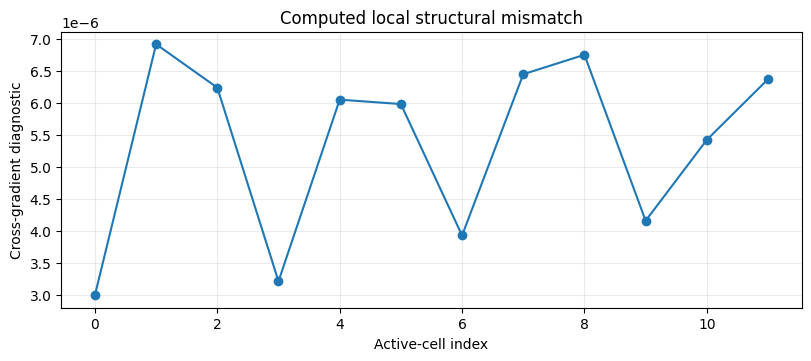

In [9]:
# Plot the computed cell diagnostic.
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
d = np.asarray(r["cell_centre_cross_gradient"])
ax.plot(np.arange(len(d)), d, "o-")
ax.set(
    xlabel="Active-cell index", ylabel="Cross-gradient diagnostic", title="Computed local structural mismatch"
)
ax.grid(alpha=0.25)
plt.show()


### Figure interpretation

Each marker is one active-cell contribution in mesh order. The plot shows why an aggregate norm can hide where the penalty originates, while also exposing this view's limit: coordinates are absent. Zero contributions are compatible with aligned gradients and locally flat fields. The figure evaluates the stated prior on an authored pair; it cannot resolve the inverse hypothesis or establish a shared geological boundary.




## Results

**Answer:** The authored twelve-cell pair gives objective 0.01277025 and finite-difference directional derivative gap 8.30e-08. This is a local regularizer calculation; no observations were inverted.

## Summary

Cross-gradient expresses a shared-structure hypothesis, but its values are not uniquely diagnostic. Flatness, alignment, scale and discretization matter. Assess identifiability with both modality-specific data sensitivities, noise and independent geology.

## References

- Cockett et al. (2015), [SimPEG](https://doi.org/10.1016/j.cageo.2015.09.015)
- [SimPEG cross-gradient tutorial](https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html)
- `data-pipeline/joint_survey_plan.py`; `data-pipeline/joint_survey_structure.py`
